In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from matplotlib import rcParams         # 设置字体
rcParams['font.family'] = 'STHeiti'

In [10]:
# 1. 生成模拟数据 (y = 2*x + 1 + noise)
np.random.seed(26)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.randn(50) * 2
print(X)
print(y)

[ 0.          0.20408163  0.40816327  0.6122449   0.81632653  1.02040816
  1.2244898   1.42857143  1.63265306  1.83673469  2.04081633  2.24489796
  2.44897959  2.65306122  2.85714286  3.06122449  3.26530612  3.46938776
  3.67346939  3.87755102  4.08163265  4.28571429  4.48979592  4.69387755
  4.89795918  5.10204082  5.30612245  5.51020408  5.71428571  5.91836735
  6.12244898  6.32653061  6.53061224  6.73469388  6.93877551  7.14285714
  7.34693878  7.55102041  7.75510204  7.95918367  8.16326531  8.36734694
  8.57142857  8.7755102   8.97959184  9.18367347  9.3877551   9.59183673
  9.79591837 10.        ]
[ 1.39198642 -2.47430954  3.24389749  3.54878609  2.17492882  3.58431798
  3.39084169  0.33797864  2.67674502  5.91871439  5.40031325  2.86118887
  7.81047227  4.71394099  4.86385908  5.05849459  6.36194332 13.43062605
  9.34217721 12.93132395  9.30091551 10.11870406  8.03972397 12.4748126
 13.71263333 12.36934527 12.89133526 12.44757647 13.03167157 14.45725775
 15.3115414  11.34008853 1

In [11]:
# 2. 从零实现最小二乘法
def least_squares(x, y):
    x_mean, y_mean = np.mean(x), np.mean(y)
    # 根据公式计算 w 和 b
    w = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    b = y_mean - w * x_mean
    return w, b

w, b = least_squares(X, y)
print(f"拟合结果: w = {w:.3f}, b = {b:.3f}")

拟合结果: w = 1.988, b = 1.077


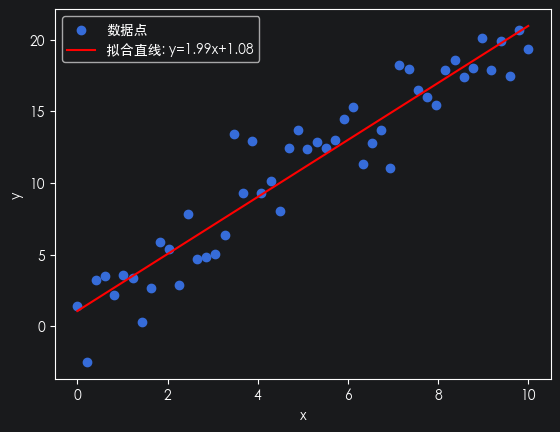

In [12]:
# 3. 可视化
plt.scatter(X, y, label='数据点')
plt.plot(X, w * X + b, color='red', label=f'拟合直线: y={w:.2f}x+{b:.2f}')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 对数逻辑回归

In [24]:
# 1. 生成二分类数据集
X, y = make_classification(n_samples=100, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=42)
y = y.reshape(-1, 1)
print(X.shape)
print(y.shape)

(100, 2)
(100, 1)


In [25]:
# 2. 从零实现逻辑回归
class LogisticRegressionScratch:
    def __init__(self, lr=0.1, n_iter=1000):
        self.lr = lr            # 学习率（梯度下降的步长）
        self.n_iter = n_iter        # 迭代次数
        self.W = None
        self.b = None

    # 核心：Sigmoid 函数——将线性回归的输出 z 映射到 (0,1) 概率区间
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.W = np.zeros((n_features, 1))
        self.b = 0

        for _ in range(self.n_iter):
            # 前向传播
            linear_model = np.dot(X, self.W) + self.b       # 线性组合：z = X·W + b
            y_pred = self.sigmoid(linear_model)

            # 计算梯度 (dLoss/dW, dLoss/db)
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)

            # 更新参数
            self.W -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        linear_model = np.dot(X, self.W) + self.b
        y_pred = self.sigmoid(linear_model)
        return (y_pred >= 0.5).astype(int)

In [17]:
# 3. 训练并预测
model = LogisticRegressionScratch(lr=0.1, n_iter=1000)
model.fit(X, y)
predictions = model.predict(X)
print(f"训练集准确率: {np.mean(predictions == y) * 100:.2f}%")

训练集准确率: 100.00%


## 线性判别分析LDA

In [21]:
# 1. 生成数据
X, y = make_classification(n_samples=100, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=42)

In [19]:
# 2. 从零实现LDA
class LDA:
    def fit(self, X, y):
        # 按类别分开
        X1, X2 = X[y == 0], X[y == 1]
        # 计算各类别的均值向量
        mu1, mu2 = np.mean(X1, axis=0), np.mean(X2, axis=0)
        # 计算类内散度矩阵 S_w
        S_w = np.dot((X1 - mu1).T, (X1 - mu1)) + np.dot((X2 - mu2).T, (X2 - mu2))
        # 计算投影方向 w
        self.w = np.dot(np.linalg.inv(S_w), (mu1 - mu2))
        # 计算决策阈值
        self.threshold = 0.5 * np.dot(self.w, (mu1 + mu2))

    def predict(self, X):
        projections = np.dot(X, self.w)
        return (projections >= self.threshold).astype(int)

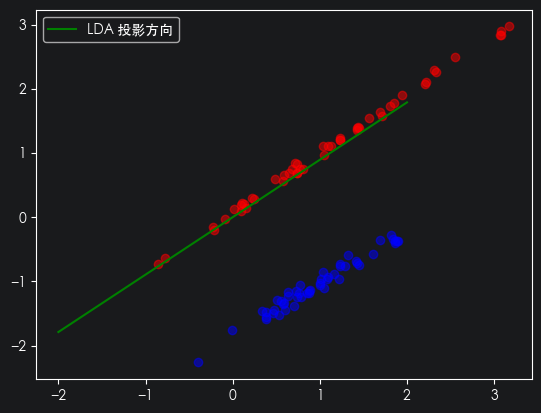

In [22]:
# 3. 训练并可视化
lda = LDA()
lda.fit(X, y)
# 绘制数据点和LDA投影方向
plt.scatter(X[y==0,0], X[y==0,1], color='blue', alpha=0.5)
plt.scatter(X[y==1,0], X[y==1,1], color='red', alpha=0.5)
# 绘制投影直线
x_plot = np.linspace(-2, 2, 10)
y_plot = -(lda.w[0] / lda.w[1]) * x_plot
plt.plot(x_plot, y_plot, color='green', label='LDA 投影方向')
plt.legend()
plt.show()

## 多分类学习

In [27]:
# 多分类学习：sklearn 官方接口示例
# 数据集：鸢尾花（3个类别，4个特征）

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier, OutputCodeClassifier
from sklearn.metrics import accuracy_score


In [30]:
# 1. 加载数据
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. 基础二分类器（逻辑回归）
base_clf = LogisticRegression(max_iter=1000, random_state=42)

In [38]:
# 3. OvO（一对一）
ovo_clf = OneVsOneClassifier(base_clf)
ovo_clf.fit(X_train, y_train)
y_pred_ovo = ovo_clf.predict(X_test)
print(f"OvO 准确率: {accuracy_score(y_test, y_pred_ovo):.4f}")


OvO 准确率: 1.0000


In [39]:
# 4. OvR（一对其余）
ovr_clf = OneVsRestClassifier(base_clf)
ovr_clf.fit(X_train, y_train)
y_pred_ovr = ovr_clf.predict(X_test)
print(f"OvR 准确率: {accuracy_score(y_test, y_pred_ovr):.4f}")

OvR 准确率: 0.9556


In [41]:
# 5. ECOC（多对多，纠错输出编码）
# code_size 控制编码长度（相对于类别数的倍数），此处设为 2
ecoc_clf = OutputCodeClassifier(base_clf, code_size=2, random_state=42)
ecoc_clf.fit(X_train, y_train)
y_pred_ecoc = ecoc_clf.predict(X_test)
print(f"ECOC (多对多) 准确率: {accuracy_score(y_test, y_pred_ecoc):.4f}")

ECOC (多对多) 准确率: 1.0000


In [37]:
# 可选：查看 ECOC 的编码矩阵（每行是一个类别的码字）
print("\nECOC 编码矩阵（-1 和 +1 组成）:")
print(ecoc_clf.code_book_)


ECOC 编码矩阵（-1 和 +1 组成）:
[[-1.  1.  1.  1. -1. -1.]
 [-1.  1.  1.  1. -1.  1.]
 [ 1. -1. -1. -1. -1.  1.]]
